In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 4.2 — Representation action

**Source:** SMSA 7.8, 2026-11-05, §4.2.14, equations (4.23)–(4.25); intertwiner diagrams §4.2.21, (4.30)–(4.31). Local source: `smsa.pdf`. Source SHA-256: `6922b174be6719adbe0bfa0573cce44f0e5a7a54c4fafd5e43969c952813b8fe`.

**Translation conventions.** SMSA reads diagrams bottom to top. These unmodified native DisCoPy drawings read top to bottom: inputs are above outputs. Tensor factors retain their left-to-right order. `f >> g` means SMSA's $g\circ f$; `f @ g` means $f\otimes g$. The empty type represents the invisible unit wire. Coupons stand for the named SMSA maps even when SMSA uses a branching vertex. No custom functions or rewrite rules are introduced.

Checks print their computed objects and comparison results and continue when a mathematical comparison is false. A comparison in a concrete tensor model establishes only that model instance.

For tensor evaluation the group wire is linearized to $A=\mathbb F[\mathbb Z_2]$, and the action on $V$ is the regular two-dimensional action. In basis order $0,1$, `rho[i,j,k]` is 1 when $k=i+j$ modulo 2. The action coupon has two inputs, unlike the one-input coupon for a fixed matrix $D(g)$.

In [1]:
from discopy import symmetric, tensor
from discopy.drawing import Equation
import numpy as np

In [2]:
A, V = map(symmetric.Ty, ['A', 'V'])
mu = symmetric.Box('mu', A @ A, A)
eta = symmetric.Box('eta', symmetric.Ty(), A)
rho = symmetric.Box('D', A @ V, V)
coefficients = [[[int(k == (i + j) % 2) for k in range(2)] for j in range(2)] for i in range(2)]
F = tensor.Functor({A: 2, V: 2}, {mu: coefficients, eta: [1, 0], rho: coefficients}, dom=symmetric.Category(), dtype=int)
combined = (mu @ symmetric.Id(V)) >> rho
successive = (symmetric.Id(A) @ rho) >> rho

(4.24) action of product:
 [[[[1 0]
   [0 1]]

  [[0 1]
   [1 0]]]


 [[[0 1]
   [1 0]]

  [[1 0]
   [0 1]]]]
Successive actions:
 [[[[1 0]
   [0 1]]

  [[0 1]
   [1 0]]]


 [[[0 1]
   [1 0]]

  [[1 0]
   [0 1]]]]
Equal: True
(4.25) unit action:
 [[1 0]
 [0 1]]
Expected:
 [[1 0]
 [0 1]] 
Equal: True


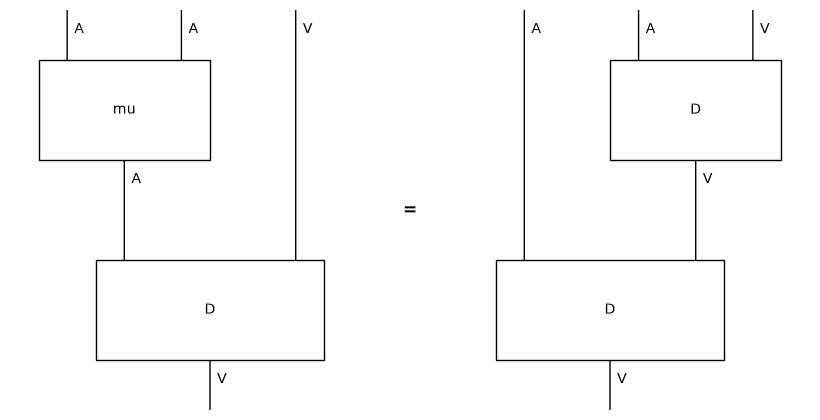

In [3]:
Equation(combined, successive).draw(figsize=(8, 4))
print('(4.24) action of product:\n', F(combined).array)
print('Successive actions:\n', F(successive).array)
print('Equal:', F(combined) == F(successive))
unit_action = (eta @ symmetric.Id(V)) >> rho
print('(4.25) unit action:\n', F(unit_action).array)
print('Expected:\n', F(symmetric.Id(V)).array, '\nEqual:', F(unit_action) == F(symmetric.Id(V)))

For (4.31), take $W=\mathbb R$ with the trivial action $D'(g)=1$. Choose $\phi(v_0,v_1)=v_0+v_1$, represented by the row matrix $[1\;1]$. The diagrams compare applying the regular action before $\phi$ with applying the trivial action after $\phi$.


(4.31) left boundary: A @ V -> W
Right boundary: A @ V -> W
Same boundary: True
phi D on group basis 0, 1 (rows), V basis 0, 1 (columns):
 [[1 1]
 [1 1]]
D' phi on the same basis:
 [[1 1]
 [1 1]]
Intertwiner equality: True
Negative control phi = [1, 0]:
phi D:
 [[1 0]
 [0 1]]
D' phi:
 [[1 0]
 [1 0]]
Intertwiner equality (expected False): False


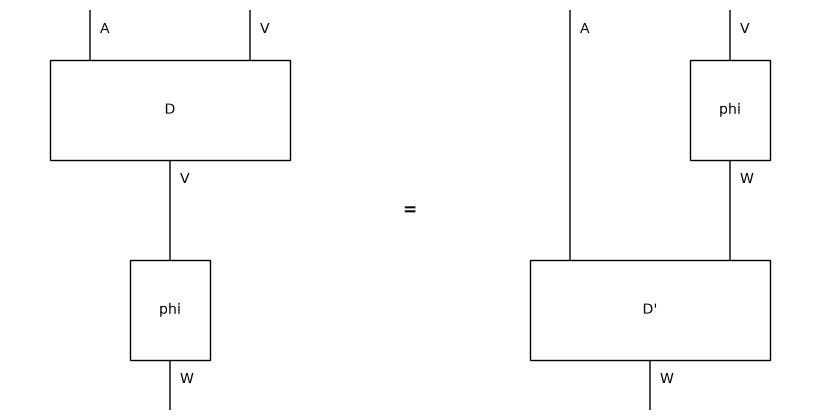

In [4]:
W = symmetric.Ty('W')
phi = symmetric.Box('phi', V, W)
rho_W = symmetric.Box("D'", A @ W, W)
intertwiner_left = rho >> phi
intertwiner_right = (symmetric.Id(A) @ phi) >> rho_W
F_intertwiner = tensor.Functor(
    {A: 2, V: 2, W: 1},
    {rho: coefficients, phi: [[1], [1]], rho_W: [[[1]], [[1]]]},
    dom=symmetric.Category(), dtype=int)
Equation(intertwiner_left, intertwiner_right).draw(figsize=(8, 4))
print('(4.31) left boundary:', intertwiner_left.dom, '->', intertwiner_left.cod)
print('Right boundary:', intertwiner_right.dom, '->', intertwiner_right.cod)
print('Same boundary:', intertwiner_left.dom == intertwiner_right.dom and intertwiner_left.cod == intertwiner_right.cod)
print('phi D on group basis 0, 1 (rows), V basis 0, 1 (columns):\n', F_intertwiner(intertwiner_left).array)
print("D' phi on the same basis:\n", F_intertwiner(intertwiner_right).array)
print('Intertwiner equality:', F_intertwiner(intertwiner_left) == F_intertwiner(intertwiner_right))
F_control = tensor.Functor(
    {A: 2, V: 2, W: 1},
    {rho: coefficients, phi: [[1], [0]], rho_W: [[[1]], [[1]]]},
    dom=symmetric.Category(), dtype=int)
print('Negative control phi = [1, 0]:')
print('phi D:\n', F_control(intertwiner_left).array)
print("D' phi:\n", F_control(intertwiner_right).array)
print('Intertwiner equality (expected False):', F_control(intertwiner_left) == F_control(intertwiner_right))


Here $W=\mathbb R$ carries the trivial action $D'(g)=1$, and $\phi(v_0,v_1)=v_0+v_1$. Thus $\phi$ adds the two components that the regular action permutes. The two printed $2\times2$ arrays evaluate (4.31) on both group basis elements and both vector basis elements. With the replacement $\phi(v_0,v_1)=v_0$, the arrays differ for the nonidentity group element. These are exact checks in the chosen $\mathbb Z_2$ model.
